In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Lib Imported Successfully")

Lib Imported Successfully


In [2]:
print("Current Folder:")
print(os.getcwd())

print("\nFiles Available:")
print(os.listdir())

Current Folder:
C:\Users\asus\OneDrive\Desktop\Fintect DA Project

Files Available:
['.ipynb_checkpoints', 'fintech_customer_transactions_50000.csv', 'Fintech_Customer_Transaction_Analysis.ipynb']


In [4]:
# load Data Set 
df=pd.read_csv("fintech_customer_transactions_50000.csv")

# display first 5 row
df.head()

,transaction_id,customer_id,transaction_amount,transaction_type,payment_type,transaction_timestamp,merchant_id,merchant_name,location,transaction_status,is_fraud
0,TXN0000001,CUST00952,3465.72,Credit,Debit,2025-02-02 13:50:18,M008,Grocery Store,Pune,Success,0
1,TXN0000002,CUST00158,393.22,Debit,Debit,2025-10-10 11:51:17,M002,Flipkart,Mumbai,Success,0
2,TXN0000003,CUST00151,1846.54,Credit,Credit,2025-08-27 22:02:47,M015,Online Gaming,Mumbai,Success,0
3,TXN0000004,CUST01057,2429.74,Debit,Net Banking,2025-06-10 04:34:30,M006,Zomato,Kolkata,Success,0
4,TXN0000005,CUST01378,495.00,Debit,Net Banking,2025-06-08 01:12:48,M005,Swiggy,Pune,Success,0


In [5]:
# check dataset shape
print("Dataset Shape:",df.shape)

Dataset Shape: (50000, 11)


In [6]:
# check total rows
print("\nTotal Rows:",df.shape[0])


Total Rows: 50000


In [7]:
# check total colums
print("Total Colums:",df.shape[1])

Total Colums: 11


In [8]:
# Display Colums Names
print("\nColumn Names:",df.columns.tolist())


Column Names: ['transaction_id', 'customer_id', 'transaction_amount', 'transaction_type', 'payment_type', 'transaction_timestamp', 'merchant_id', 'merchant_name', 'location', 'transaction_status', 'is_fraud']


In [9]:
# Dataset Info
print("\nDataset Info:",df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   transaction_id         50000 non-null  object 
 1   customer_id            50000 non-null  object 
 2   transaction_amount     50000 non-null  float64
 3   transaction_type       50000 non-null  object 
 4   payment_type           49960 non-null  object 
 5   transaction_timestamp  50000 non-null  object 
 6   merchant_id            50000 non-null  object 
 7   merchant_name          49950 non-null  object 
 8   location               49880 non-null  object 
 9   transaction_status     50000 non-null  object 
 10  is_fraud               50000 non-null  int64  
dtypes: float64(1), int64(1), object(9)
memory usage: 4.2+ MB

Dataset Info: None


In [11]:
# check mmissing values
print("Missing Values:",df.isnull().sum())

# check total mmissing values
print("\nTotal Missing Values:",df.isnull().sum().sum())

# check  mmissing values Percentage
print("\nMissing Values Percentage:",(df.isnull().sum()/len(df))*100)

Missing Values: transaction_id             0
customer_id                0
transaction_amount         0
transaction_type           0
payment_type              40
transaction_timestamp      0
merchant_id                0
merchant_name             50
location                 120
transaction_status         0
is_fraud                   0
dtype: int64

Total Missing Values: 210

Missing Values Percentage: transaction_id           0.00
customer_id              0.00
transaction_amount       0.00
transaction_type         0.00
payment_type             0.08
transaction_timestamp    0.00
merchant_id              0.00
merchant_name            0.10
location                 0.24
transaction_status       0.00
is_fraud                 0.00
dtype: float64


In [12]:
# Check Duplicate Records
print("Total  Duplicate Rows:",df.duplicated().sum())

# check Duplicate Transaction IDs
print("Dupkicate Transaction IDs:",df['transaction_id'].duplicated().sum())

Total  Duplicate Rows: 0
Dupkicate Transaction IDs: 0


In [16]:
# check merchant validation ID and merchant name mapping
merchant_check=df.groupby('merchant_id')['merchant_name'].nunique()

print('MerchantMapping Check')
print(merchant_check)

print("\nTotal Merchant IDs:",df['merchant_id'].nunique())

print("Merchant IDs with Multiple Names:",(merchant_check>1).sum())

MerchantMapping Check
merchant_id
M001    1
M002    1
M003    1
M004    1
M005    1
M006    1
M007    1
M008    1
M009    1
M010    1
M011    1
M012    1
M013    1
M014    1
M015    1
Name: merchant_name, dtype: int64

Total Merchant IDs: 15
Merchant IDs with Multiple Names: 0


In [20]:
# fill missing merchant names
merchant_mapping=df.groupby('merchant_id')['merchant_name'].first()
df['merchant_name']=df['merchant_name'].fillna(
    df['merchant_id'].map(merchant_mapping)
)

# fill missing values
df['payment_type']=df['payment_type'].fillna('Unknown')

# fill missing location
df['location']=df['location'].fillna('Unknown')

# check missing values again 
print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
transaction_id           0
customer_id              0
transaction_amount       0
transaction_type         0
payment_type             0
transaction_timestamp    0
merchant_id              0
merchant_name            0
location                 0
transaction_status       0
is_fraud                 0
dtype: int64


In [21]:
# Convert Timestamp into Datetime

df['transaction_timestamp'] = pd.to_datetime(
    df['transaction_timestamp']
)

# Check Data Type

print(df['transaction_timestamp'].dtype)


datetime64[ns]


In [22]:
# Extract Date and Time Features

df['transaction_date'] = df['transaction_timestamp'].dt.date

df['year'] = df['transaction_timestamp'].dt.year

df['month'] = df['transaction_timestamp'].dt.month

df['month_name'] = df['transaction_timestamp'].dt.month_name()

df['day'] = df['transaction_timestamp'].dt.day

df['day_of_week'] = df['transaction_timestamp'].dt.day_name()

df['hour'] = df['transaction_timestamp'].dt.hour

df['is_weekend'] = df['transaction_timestamp'].dt.dayofweek >= 5

print("Date and Time Features Created Successfully")

Date and Time Features Created Successfully


In [24]:
print("Updated Dataset Shape:", df.shape)

df[['transaction_timestamp',
    'transaction_date',
    'year',
    'month_name',
    'day_of_week',
    'hour',
    'is_weekend']].head(10)

Updated Dataset Shape: (50000, 19)


,transaction_timestamp,transaction_date,year,month_name,day_of_week,hour,is_weekend
0,2025-02-02 13:50:18,2025-02-02,2025,February,Sunday,13,True
1,2025-10-10 11:51:17,2025-10-10,2025,October,Friday,11,False
2,2025-08-27 22:02:47,2025-08-27,2025,August,Wednesday,22,False
3,2025-06-10 04:34:30,2025-06-10,2025,June,Tuesday,4,False
4,2025-06-08 01:12:48,2025-06-08,2025,June,Sunday,1,True
5,2025-11-10 09:19:03,2025-11-10,2025,November,Monday,9,False
6,2025-02-01 08:53:01,2025-02-01,2025,February,Saturday,8,True
7,2025-09-12 12:56:38,2025-09-12,2025,September,Friday,12,False
8,2025-03-15 12:52:23,2025-03-15,2025,March,Saturday,12,True
9,2025-02-04 08:59:36,2025-02-04,2025,February,Tuesday,8,False


In [25]:
# Transaction Amount Statistical Analysis
print("Transaction Amount Statistical")

print("\nTotal Transaction Amount:")
print(df['transaction_amount'].sum())

print("\nAverage Transaction Amount:")
print(df['transaction_amount'].mean())

print("\nMedian Transaction Amount:")
print(df['transaction_amount'].median())

print("\nMinimum Transaction Amount:")
print(df['transaction_amount'].min())

print("\nMaximum Transaction Amount:")
print(df['transaction_amount'].max())

print("\nStandard Deviation:")
print(df['transaction_amount'].std())

Transaction Amount Statistical

Total Transaction Amount:
82292649.36999999

Average Transaction Amount:
1645.8529873999998

Median Transaction Amount:
1097.09

Minimum Transaction Amount:
27.31

Maximum Transaction Amount:
48844.74

Standard Deviation:
1861.3884638002044


In [26]:
# complete statistical summary
df['transaction_amount'].describe()

count    50000.000000
mean      1645.852987
std       1861.388464
min         27.310000
25%        598.547500
50%       1097.090000
75%       2009.187500
max      48844.740000
Name: transaction_amount, dtype: float64

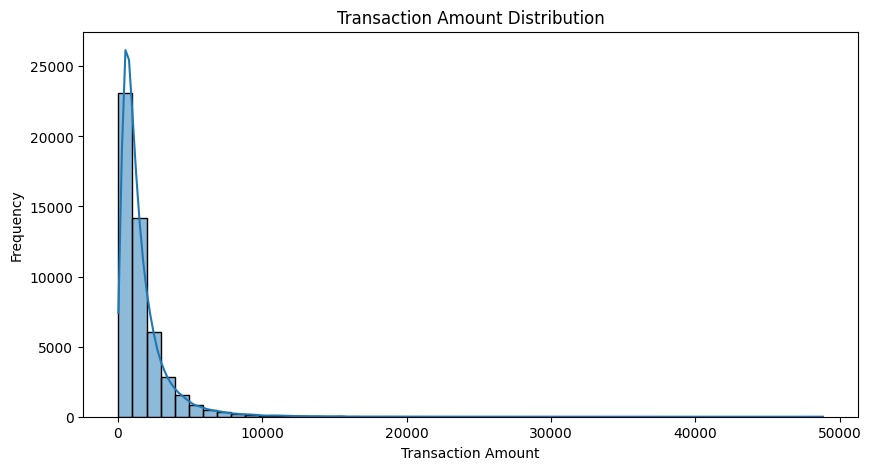

In [29]:
# Transaction Amount Distribution
plt.figure(figsize=(10, 5))
sns.histplot(
    df['transaction_amount'],
    bins=50,
    kde=True
)
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

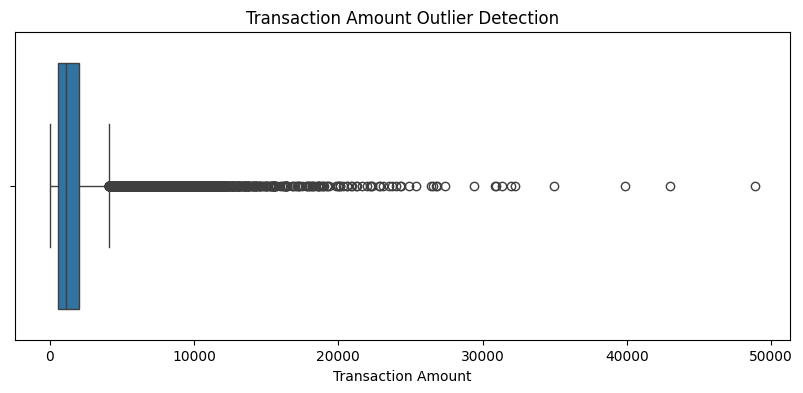

In [28]:
# Transaction Amount Outlier Detection

plt.figure(figsize=(10, 4))

sns.boxplot(x=df['transaction_amount'])

plt.title("Transaction Amount Outlier Detection")
plt.xlabel("Transaction Amount")

plt.show()

In [30]:
# Calculate Q1 and Q3

Q1 = df['transaction_amount'].quantile(0.25)
Q3 = df['transaction_amount'].quantile(0.75)

# Calculate IQR

IQR = Q3 - Q1

# Calculate Lower and Upper Limit

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Detect Outliers

outliers = df[
    (df['transaction_amount'] < lower_limit) |
    (df['transaction_amount'] > upper_limit)
]

# Display Results

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("Total Outliers:", len(outliers))

print("Outlier Percentage:", (len(outliers)/len(df))*100)

Q1: 598.5474999999999
Q3: 2009.1875
IQR: 1410.64
Lower Limit: -1517.4125000000001
Upper Limit: 4125.1475
Total Outliers: 3531
Outlier Percentage: 7.062


In [31]:
# Display Top 10 Outlier Transactions

outliers.sort_values(
    by='transaction_amount',
    ascending=False
).head(10)

,transaction_id,customer_id,transaction_amount,transaction_type,payment_type,transaction_timestamp,merchant_id,merchant_name,location,transaction_status,is_fraud,transaction_date,year,month,month_name,day,day_of_week,hour,is_weekend
46265,TXN0046266,CUST00494,48844.74,Debit,Credit,2025-08-20 10:11:33,M007,Fuel Station,Delhi,Success,0,2025-08-20,2025,8,August,20,Wednesday,10,False
12898,TXN0012899,CUST01951,42957.79,Credit,Credit,2025-02-06 00:04:31,M013,Fashion Store,Jaipur,Success,0,2025-02-06,2025,2,February,6,Thursday,0,False
31034,TXN0031035,CUST01484,39866.92,Credit,Debit,2025-11-09 03:45:25,M005,Swiggy,Hyderabad,Success,0,2025-11-09,2025,11,November,9,Sunday,3,True
18505,TXN0018506,CUST01089,34936.14,Debit,Debit,2025-03-04 22:42:14,M015,Online Gaming,Delhi,Success,0,2025-03-04,2025,3,March,4,Tuesday,22,False
33524,TXN0033525,CUST00702,32220.99,Debit,UPI,2025-07-24 18:02:50,M013,Fashion Store,Bengaluru,Success,0,2025-07-24,2025,7,July,24,Thursday,18,False
34913,TXN0034914,CUST01632,31953.77,Credit,UPI,2025-05-27 17:08:01,M008,Grocery Store,Mumbai,Success,0,2025-05-27,2025,5,May,27,Tuesday,17,False
5025,TXN0005026,CUST00813,31349.63,Debit,Debit,2025-09-14 06:23:57,M008,Grocery Store,Hyderabad,Success,0,2025-09-14,2025,9,September,14,Sunday,6,True
18523,TXN0018524,CUST00857,30896.79,Credit,UPI,2025-09-15 02:50:17,M012,Restaurant,Bengaluru,Success,0,2025-09-15,2025,9,September,15,Monday,2,False
4122,TXN0004123,CUST00963,30840.44,Credit,Debit,2025-10-15 21:25:03,M013,Fashion Store,Chennai,Success,0,2025-10-15,2025,10,October,15,Wednesday,21,False
30947,TXN0030948,CUST01029,29390.05,Debit,Debit,2025-09-03 13:34:13,M001,Amazon,Ahmedabad,Success,0,2025-09-03,2025,9,September,3,Wednesday,13,False


In [32]:
# Fraud Analysis of Outliers

print("Outlier Fraud Distribution:")

print(outliers['is_fraud'].value_counts())

print("\nFraud Percentage in Outliers:")

print(
    outliers['is_fraud'].value_counts(normalize=True) * 100
)

Outlier Fraud Distribution:
is_fraud
0    3461
1      70
Name: count, dtype: int64

Fraud Percentage in Outliers:
is_fraud
0    98.017559
1     1.982441
Name: proportion, dtype: float64


In [33]:
# Fraud Analysis by Transaction Type

fraud_analysis = df.groupby(
    'transaction_type'
)['is_fraud'].value_counts().unstack(fill_value=0)

print("Fraud Analysis by Transaction Type:")
print(fraud_analysis)

Fraud Analysis by Transaction Type:
is_fraud              0    1
transaction_type            
Credit             8841  144
Debit             40254  761


In [34]:
# Calculate Fraud Percentage by Transaction Type

fraud_percentage = (
    df.groupby('transaction_type')['is_fraud']
    .mean() * 100
)

print("Fraud Percentage by Transaction Type:")
print(fraud_percentage)

Fraud Percentage by Transaction Type:
transaction_type
Credit    1.602671
Debit     1.855419
Name: is_fraud, dtype: float64


In [35]:
# Fraud Analysis by Merchant

merchant_fraud = df.groupby('merchant_name')['is_fraud'].sum()

merchant_fraud = merchant_fraud.sort_values(
    ascending=False
)

print("Merchant-wise Fraud Analysis:")
print(merchant_fraud)

Merchant-wise Fraud Analysis:
merchant_name
Travel Agency        116
Online Gaming        101
Pharmacy              61
Walmart               60
Fashion Store         58
Swiggy                57
Zomato                57
Flipkart              55
Electronics Store     53
Restaurant            51
Hotel                 50
Grocery Store         50
Uber                  48
Amazon                47
Fuel Station          41
Name: is_fraud, dtype: int64


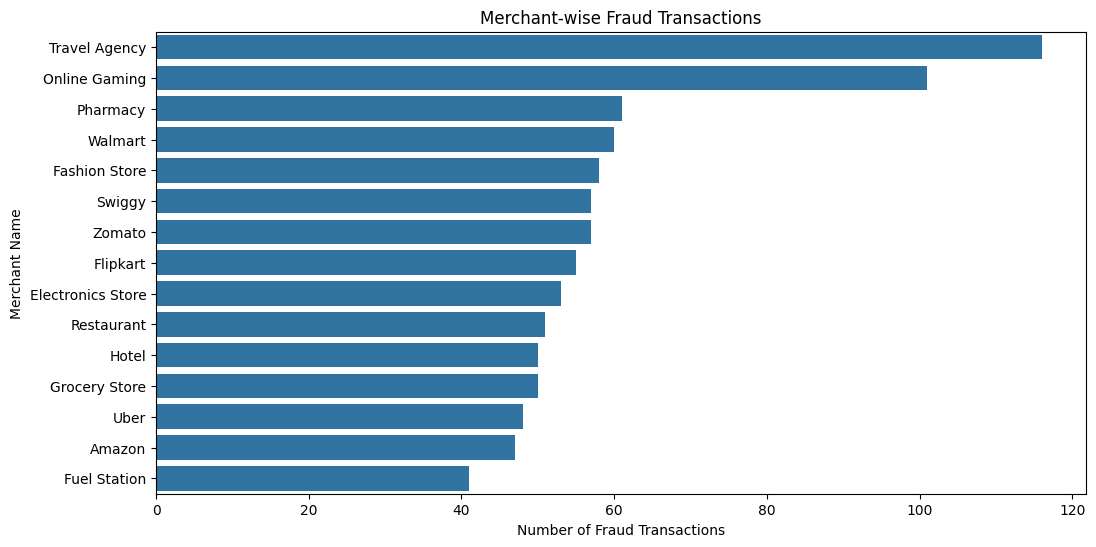

In [36]:
# Merchant-wise Fraud Analysis Visualization

plt.figure(figsize=(12, 6))

sns.barplot(
    x=merchant_fraud.values,
    y=merchant_fraud.index
)

plt.title("Merchant-wise Fraud Transactions")
plt.xlabel("Number of Fraud Transactions")
plt.ylabel("Merchant Name")

plt.show()

In [37]:
# Fraud Analysis by Payment Type

payment_fraud = df.groupby(
    'payment_type'
)['is_fraud'].sum()

payment_fraud = payment_fraud.sort_values(
    ascending=False
)

print("Payment Type-wise Fraud Analysis:")
print(payment_fraud)

Payment Type-wise Fraud Analysis:
payment_type
UPI            326
Debit          245
Credit         243
Net Banking     91
Unknown          0
Name: is_fraud, dtype: int64


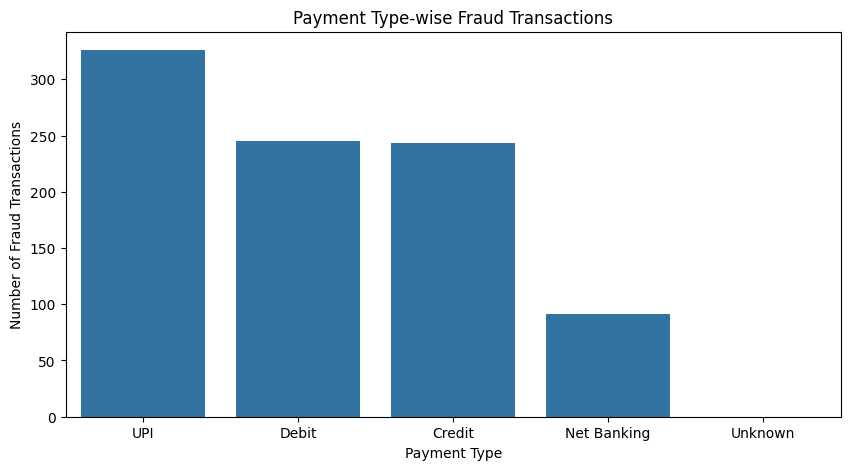

In [38]:
# Payment Type-wise Fraud Visualization

plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_fraud.index,
    y=payment_fraud.values
)

plt.title("Payment Type-wise Fraud Transactions")
plt.xlabel("Payment Type")
plt.ylabel("Number of Fraud Transactions")

plt.show()

In [39]:
# Fraud Analysis by Location

location_fraud = df.groupby(
    'location'
)['is_fraud'].sum()

location_fraud = location_fraud.sort_values(
    ascending=False
)

print("Location-wise Fraud Analysis:")
print(location_fraud)

Location-wise Fraud Analysis:
location
Mumbai       163
Bengaluru    123
Pune         111
Delhi        101
Hyderabad     89
Chennai       81
Nagpur        72
Ahmedabad     58
Jaipur        56
Kolkata       50
Unknown        1
Name: is_fraud, dtype: int64


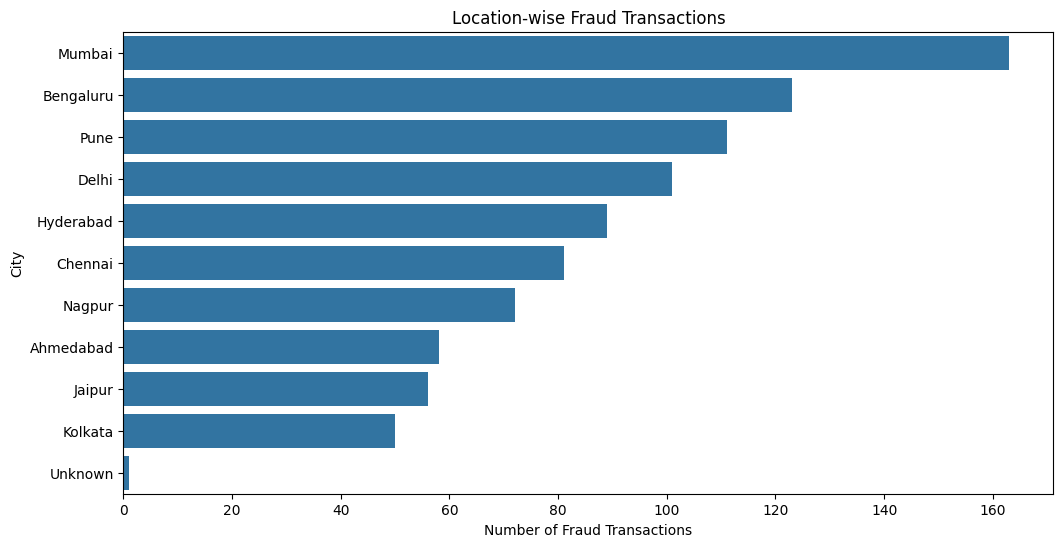

In [40]:
# Location-wise Fraud Visualization

plt.figure(figsize=(12, 6))

sns.barplot(
    x=location_fraud.values,
    y=location_fraud.index
)

plt.title("Location-wise Fraud Transactions")
plt.xlabel("Number of Fraud Transactions")
plt.ylabel("City")

plt.show()

In [41]:
# Fraud Analysis by Hour

hourly_fraud = df.groupby('hour')['is_fraud'].sum()

print("Hour-wise Fraud Analysis:")
print(hourly_fraud.sort_values(ascending=False))

Hour-wise Fraud Analysis:
hour
2     76
3     72
23    68
4     67
1     64
0     58
16    41
19    34
17    33
12    33
20    32
21    32
15    29
11    28
6     27
18    27
10    26
5     26
13    26
7     24
8     24
22    24
14    18
9     16
Name: is_fraud, dtype: int64


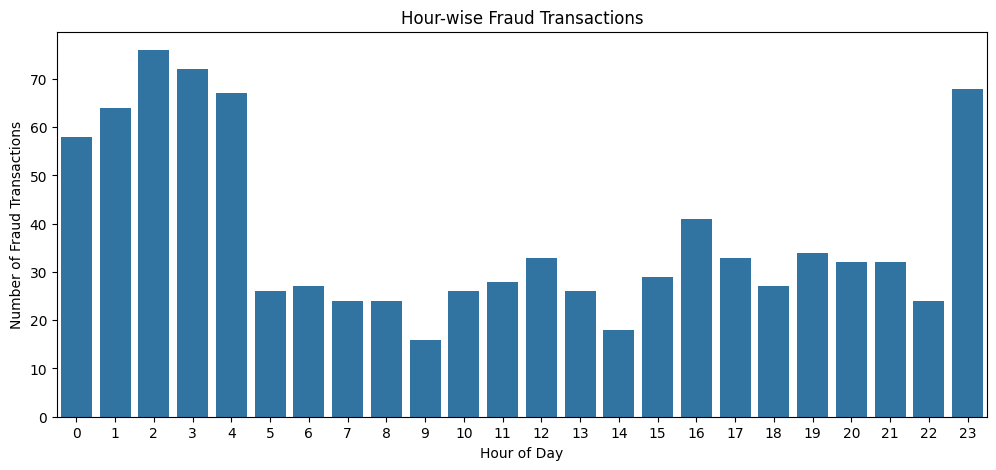

In [42]:
plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_fraud.index,
    y=hourly_fraud.values
)

plt.title("Hour-wise Fraud Transactions")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Fraud Transactions")

plt.show()

In [43]:
# Fraud Analysis by Weekend

weekend_fraud = df.groupby('is_weekend')['is_fraud'].sum()

print("Weekend vs Weekday Fraud Analysis:")
print(weekend_fraud)

Weekend vs Weekday Fraud Analysis:
is_weekend
False    646
True     259
Name: is_fraud, dtype: int64


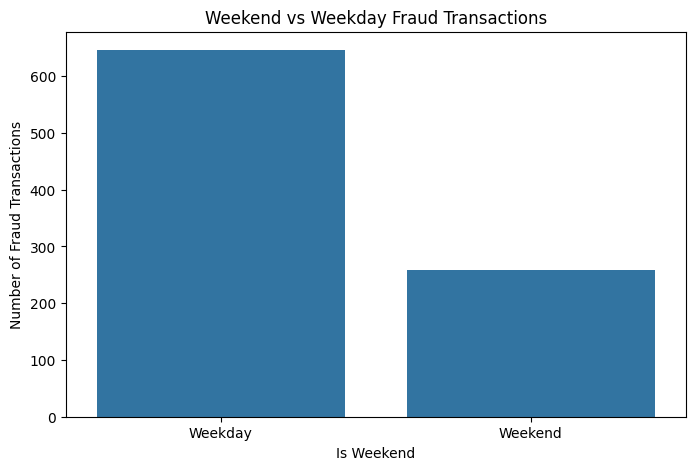

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=weekend_fraud.index,
    y=weekend_fraud.values
)

plt.title("Weekend vs Weekday Fraud Transactions")
plt.xlabel("Is Weekend")
plt.ylabel("Number of Fraud Transactions")

plt.xticks([0, 1], ['Weekday', 'Weekend'])

plt.show()

In [45]:
# Fraud Analysis by Month

monthly_fraud = df.groupby('month_name')['is_fraud'].sum()

print("Month-wise Fraud Analysis:")
print(monthly_fraud.sort_values(ascending=False))

Month-wise Fraud Analysis:
month_name
September    95
February     88
January      81
August       81
May          74
June         73
October      72
December     72
April        71
March        71
November     68
July         59
Name: is_fraud, dtype: int64


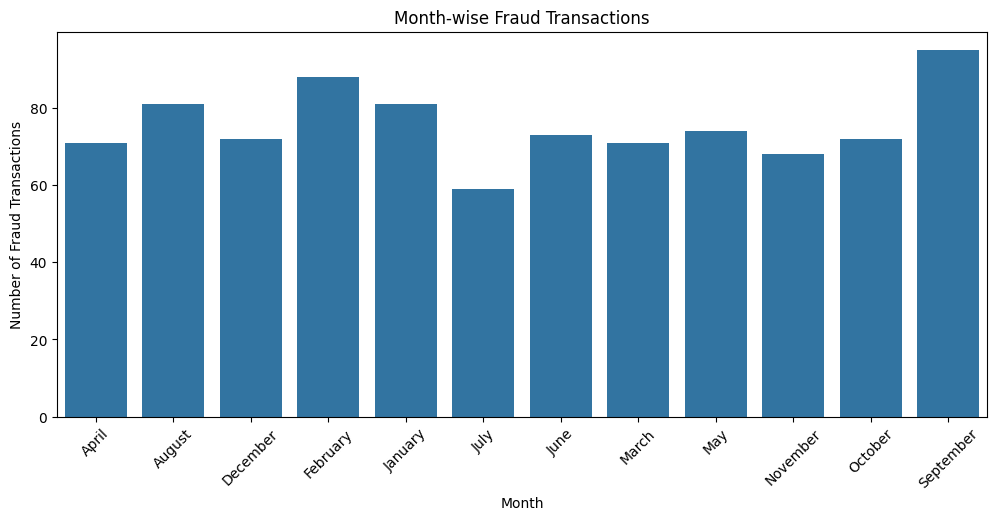

In [46]:
plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_fraud.index,
    y=monthly_fraud.values
)

plt.title("Month-wise Fraud Transactions")
plt.xlabel("Month")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(rotation=45)

plt.show()

In [47]:
# Fraud Analysis by Transaction Amount

amount_analysis = df.groupby('is_fraud')['transaction_amount'].mean()

print("Average Transaction Amount:")
print(amount_analysis)

Average Transaction Amount:
is_fraud
0    1645.411304
1    1669.813702
Name: transaction_amount, dtype: float64


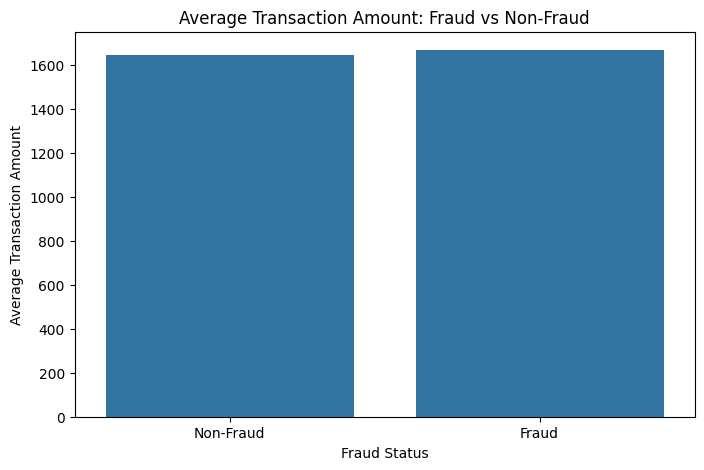

In [48]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=amount_analysis.index,
    y=amount_analysis.values
)

plt.title("Average Transaction Amount: Fraud vs Non-Fraud")
plt.xlabel("Fraud Status")
plt.ylabel("Average Transaction Amount")

plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])

plt.show()

In [49]:
# Fraud Analysis by Amount Range

df['amount_range'] = pd.cut(
    df['transaction_amount'],
    bins=[0, 500, 1000, 2000, 3000, 5000, float('inf')],
    labels=['0-500', '500-1000', '1000-2000',
            '2000-3000', '3000-5000', '5000+']
)

In [50]:
amount_fraud = (
    df.groupby('amount_range', observed=False)['is_fraud']
    .mean() * 100
)

print("Fraud Percentage by Amount Range:")
print(amount_fraud)

Fraud Percentage by Amount Range:
amount_range
0-500        1.803880
500-1000     1.842359
1000-2000    1.872659
2000-3000    1.476688
3000-5000    1.893408
5000+        1.972819
Name: is_fraud, dtype: float64


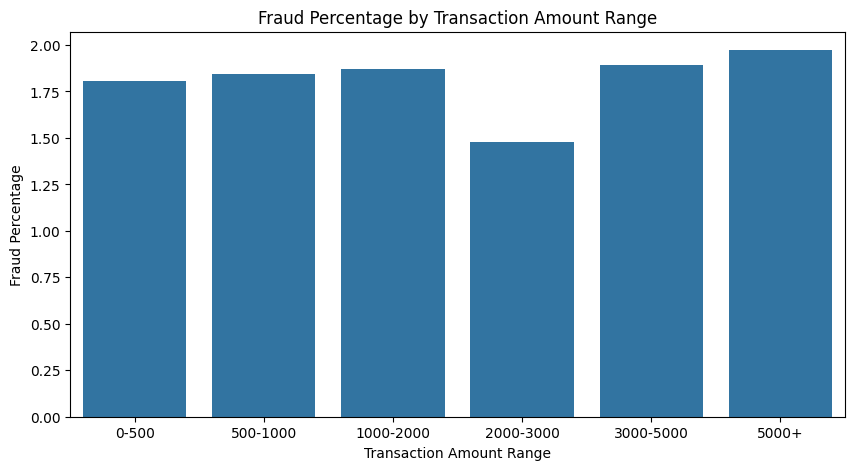

In [51]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=amount_fraud.index,
    y=amount_fraud.values
)

plt.title("Fraud Percentage by Transaction Amount Range")
plt.xlabel("Transaction Amount Range")
plt.ylabel("Fraud Percentage")

plt.show()

In [52]:
# Fraud Analysis by Day of Week

df['day_name'] = df['transaction_timestamp'].dt.day_name()

day_fraud = df.groupby('day_name')['is_fraud'].sum()

day_fraud = day_fraud.sort_values(ascending=False)

print("Day-wise Fraud Analysis:")
print(day_fraud)

Day-wise Fraud Analysis:
day_name
Wednesday    139
Saturday     136
Monday       136
Thursday     132
Sunday       123
Tuesday      120
Friday       119
Name: is_fraud, dtype: int64


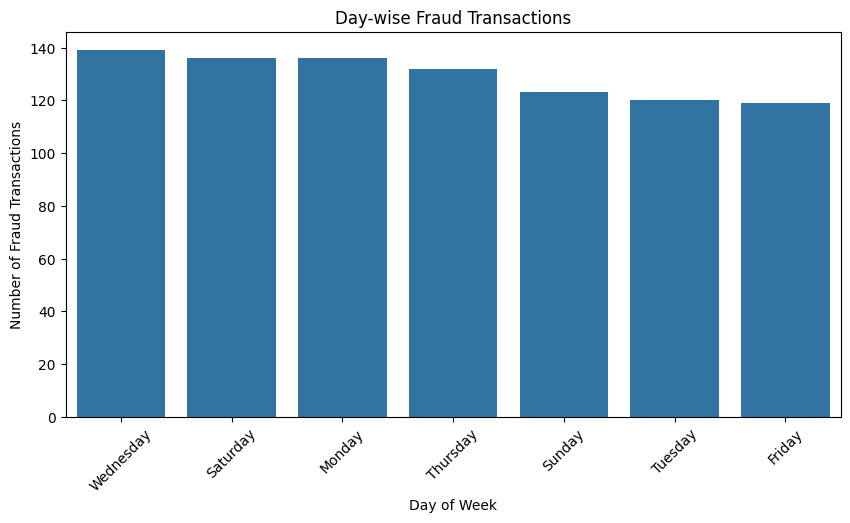

In [53]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=day_fraud.index,
    y=day_fraud.values
)

plt.title("Day-wise Fraud Transactions")
plt.xlabel("Day of Week")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(rotation=45)

plt.show()

In [54]:
# Fraud Analysis by Transaction Status

status_fraud = df.groupby(
    'transaction_status'
)['is_fraud'].sum()

status_fraud = status_fraud.sort_values(
    ascending=False
)

print("Status-wise Fraud Analysis:")
print(status_fraud)

Status-wise Fraud Analysis:
transaction_status
Success     499
Declined    219
Failed      187
Name: is_fraud, dtype: int64


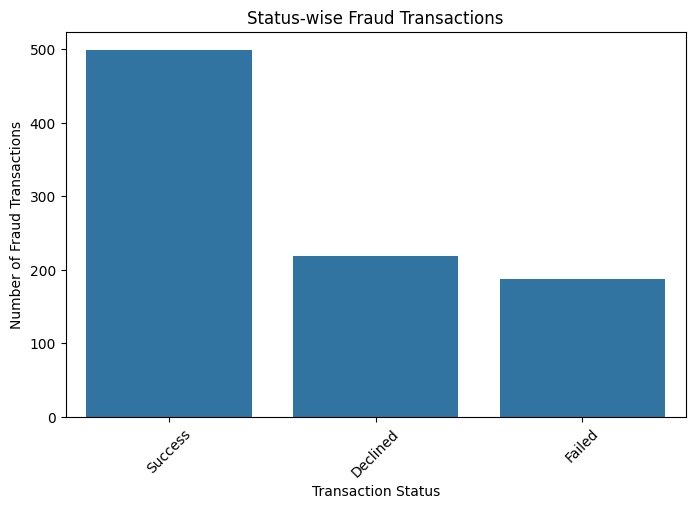

In [55]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=status_fraud.index,
    y=status_fraud.values
)

plt.title("Status-wise Fraud Transactions")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(rotation=45)

plt.show()

Merchant-wise Fraud Percentage:
merchant_name
Travel Agency        3.393798
Online Gaming        2.969715
Pharmacy             1.792536
Walmart              1.784121
Fashion Store        1.750679
Swiggy               1.725704
Zomato               1.703018
Flipkart             1.659125
Electronics Store    1.621291
Restaurant           1.550623
Name: is_fraud, dtype: float64


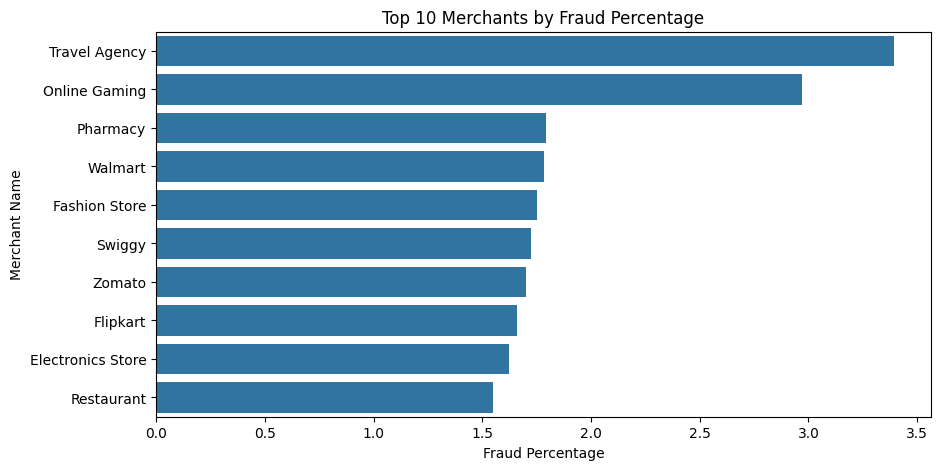

In [56]:

# Fraud Percentage by Merchant

merchant_rate = (
    df.groupby('merchant_name')['is_fraud']
    .mean() * 100
)

merchant_rate = merchant_rate.sort_values(
    ascending=False
).head(10)

print("Merchant-wise Fraud Percentage:")
print(merchant_rate)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=merchant_rate.values,
    y=merchant_rate.index
)

plt.title("Top 10 Merchants by Fraud Percentage")
plt.xlabel("Fraud Percentage")
plt.ylabel("Merchant Name")

plt.show()


Payment Type-wise Fraud Percentage:
payment_type
UPI            1.864135
Debit          1.833695
Net Banking    1.803766
Credit         1.727570
Unknown        0.000000
Name: is_fraud, dtype: float64


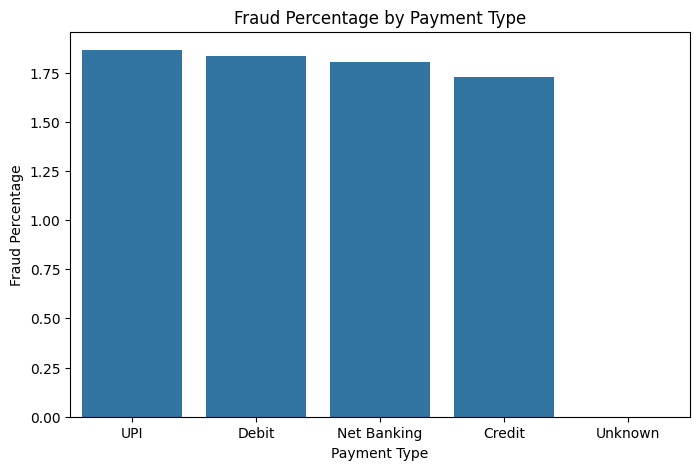

In [57]:

# Fraud Percentage by Payment Type

payment_rate = (
    df.groupby('payment_type')['is_fraud']
    .mean() * 100
)

payment_rate = payment_rate.sort_values(
    ascending=False
)

print("Payment Type-wise Fraud Percentage:")
print(payment_rate)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=payment_rate.index,
    y=payment_rate.values
)

plt.title("Fraud Percentage by Payment Type")
plt.xlabel("Payment Type")
plt.ylabel("Fraud Percentage")

plt.show()


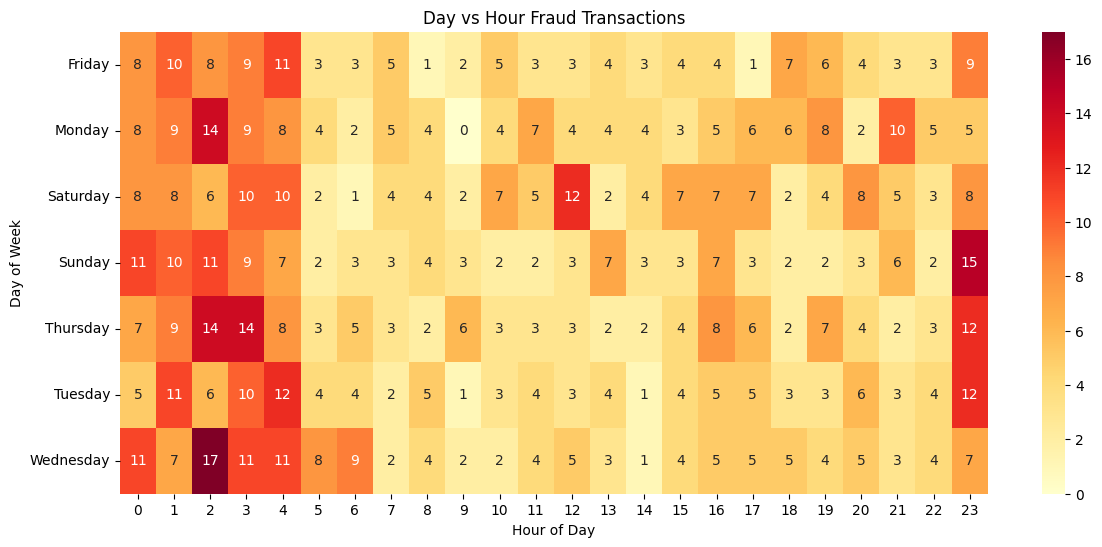

In [58]:

# Fraud Analysis by Day and Hour

fraud_heatmap = df.pivot_table(
    index='day_name',
    columns='hour',
    values='is_fraud',
    aggfunc='sum'
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    fraud_heatmap,
    annot=True,
    fmt='.0f',
    cmap='YlOrRd'
)

plt.title("Day vs Hour Fraud Transactions")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")

plt.show()
